In [2]:
%pip install tensorflow
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")

  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/384.1 MB 1.4 MB/s eta 0:04:44
   ---------------------------------------- 1.0/384.1 MB 1.8 MB/s eta 0:03:35
   ---------------------------------------- 1.8/384.1 MB 2.3 MB/s eta 0:02:47
   ---------------------------------------- 2.6/384.1 MB 2.6 MB/s eta 0:02:28
   ---------------------------------------- 3.1/384.1 MB 2.7 MB/s eta 0:

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

RANDOM_STATE = 42
EPOCHS = 20
BATCH_SIZE = 256

OUTPUT_DIR = "ANN_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(RANDOM_STATE)

print("=" * 65)
print("ANN STELLAR CLASSIFICATION ASSIGNMENT")
print("=" * 65)


ANN STELLAR CLASSIFICATION ASSIGNMENT


In [5]:
# ------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------

df = pd.read_csv(r# 3. DATA PREPROCESSING
# ------------------------------------------------

# Use astronomical measurements as input features.
# Exclude object identifiers and survey metadata.

feature_columns = [
    "alpha",
    "delta",
    "u",
    "g",
    "r",
    "i",
    "z",
    "redshift"
]

missing_columns = [
    col for col in feature_columns + ["class"]
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from dataset: {missing_columns}"
    )

df = df.dropna(subset=feature_columns + ["class"]).copy()

X = df[feature_columns].copy()
y_original = df["class"].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original)

class_names = label_encoder.classes_
num_classes = len(class_names)

print("\nInput Features:", feature_columns)
print("Output Classes:", list(class_names))
print("Number of Classes:", num_classes)
"C:\Users\vkvar\Downloads\archive (4)\star_classification.csv")

print("\nDataset Shape:", df.shape)
print("\nFirst Five Rows:")
print(df.head())

print("\nClass Distribution:")
print(df["class"].value_counts())



Dataset Shape: (100000, 18)

First Five Rows:
         obj_ID       alpha      delta         u         g         r  \
0  1.237661e+18  135.689107  32.494632  23.87882  22.27530  20.39501   
1  1.237665e+18  144.826101  31.274185  24.77759  22.83188  22.58444   
2  1.237661e+18  142.188790  35.582444  25.26307  22.66389  20.60976   
3  1.237663e+18  338.741038  -0.402828  22.13682  23.77656  21.61162   
4  1.237680e+18  345.282593  21.183866  19.43718  17.58028  16.49747   

          i         z  run_ID  rerun_ID  cam_col  field_ID   spec_obj_ID  \
0  19.16573  18.79371    3606       301        2        79  6.543777e+18   
1  21.16812  21.61427    4518       301        5       119  1.176014e+19   
2  19.34857  18.94827    3606       301        2       120  5.152200e+18   
3  20.50454  19.25010    4192       301        3       214  1.030107e+19   
4  15.97711  15.54461    8102       301        3       137  6.891865e+18   

    class  redshift  plate    MJD  fiber_ID  
0  GALAXY  0.6347

In [22]:
# Define input features and target

features = ['alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift']

X = df[features].copy()

# Encode target classes into numerical labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['class'])

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(label_encoder.classes_)

Input features shape: (100000, 8)
Target shape: (100000,)

Target classes:
['GALAXY' 'QSO' 'STAR']


In [23]:
# 4. TRAIN-VALIDATION-TEST SPLIT
# ------------------------------------------------

# 60% training, 20% validation, 20% testing.
# The validation set is used to compare configurations.
# The test set is reserved for final evaluation.

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_trainval
)

# Standardize using training data only.

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("\nTraining Samples:", len(y_train))
print("Validation Samples:", len(y_val))
print("Testing Samples:", len(y_test))



Training Samples: 60000
Validation Samples: 20000
Testing Samples: 20000


In [24]:
num_classes = len(np.unique(y_train))

print("Number of classes:", num_classes)

Number of classes: 3


In [25]:

def build_ann(input_dim, hidden_layers, activation, learning_rate):

    model = tf.keras.Sequential()

    # Input layer
    model.add(tf.keras.layers.Input(shape=(input_dim,)))

    # Hidden layers
    for _ in range(hidden_layers):
        model.add(
            tf.keras.layers.Dense(32, activation=activation)
        )

    # Output layer
    model.add(
        tf.keras.layers.Dense(num_classes, activation="softmax")
    )

    # Compile model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [11]:
# ------------------------------------------------
# 6. DEFINE EXPERIMENT PARAMETERS
# ------------------------------------------------

hidden_layer_values = list(range(2, 11))

activation_functions = [
    "relu",
    "tanh",
    "sigmoid"
]

learning_rates = [
    0.0001,
    0.001,
    0.01
]

total_experiments = (
    len(hidden_layer_values)
    * len(activation_functions)
    * len(learning_rates)
)

print("\nTotal ANN Configurations:", total_experiments)



Total ANN Configurations: 81


In [ ]:
start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

computation_time = time.time() - start_time

In [26]:

# ------------------------------------------------
# 7. RUN ALL 81 EXPERIMENTS
# ------------------------------------------------

results = []
experiment_number = 0

for layers in hidden_layer_values:
    for activation in activation_functions:
        for lr in learning_rates:

            experiment_number += 1

            print(
                f"Experiment {experiment_number}/81 | "
                f"Layers={layers} | "
                f"Activation={activation} | "
                f"Learning Rate={lr}"
            )

            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(
                RANDOM_STATE + experiment_number
            )

            model = build_ann(
                input_dim=X_train.shape[1],
                hidden_layers=layers,
                activation=activation,
                learning_rate=lr
            )

            start_time = time.time()

            history = model.fit(
                X_train,
                y_train,
                validation_data=(X_val, y_val),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                verbose=0
            )

            training_time = time.time() - start_time

            # Validation predictions
            val_prob = model.predict(X_val, verbose=0)
            val_pred = np.argmax(val_prob, axis=1)

            # Calculate validation metrics
            val_accuracy = accuracy_score(y_val, val_pred)
            val_error = 1 - val_accuracy

            val_logloss = log_loss(
                y_val,
                val_prob,
                labels=np.arange(num_classes)
            )

            val_f1 = f1_score(
                y_val,
                val_pred,
                average="weighted",
                zero_division=0
            )

            # Store results
            results.append({
                "Hidden_Layers": layers,
                "Activation": activation,
                "Learning_Rate": lr,
                "Validation_Accuracy": val_accuracy,
                "Validation_Error": val_error,
                "Validation_Error_Percent": val_error * 100,
                "Validation_Log_Loss": val_logloss,
                "Validation_Weighted_F1": val_f1,
                "Training_Time_Seconds": training_time
            })

            print(
                f"Accuracy={val_accuracy:.4f} | "
                f"Error={val_error * 100:.2f}% | "
                f"Log Loss={val_logloss:.4f}"
            )

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Sort by lowest validation log loss
results_df = results_df.sort_values(
    by="Validation_Log_Loss",
    ascending=True
).reset_index(drop=True)

# Display the best configurations
print("\nTOP 10 ANN CONFIGURATIONS")
display(results_df.head(10))

# Save results
results_df.to_csv(
    "ANN_Experiment_Results.csv",
    index=False
)

results_df.to_excel(
    "ANN_Experiment_Results.xlsx",
    index=False
)

# Display the best configuration
best_result = results_df.iloc[0]

print("\nBEST ANN CONFIGURATION")
print("Hidden layers:", best_result["Hidden_Layers"])
print("Activation:", best_result["Activation"])
print("Learning rate:", best_result["Learning_Rate"])
print("Validation accuracy:", round(
    best_result["Validation_Accuracy"], 4
))
print("Validation error (%):", round(
    best_result["Validation_Error_Percent"], 2
))
print("Validation log loss:", round(
    best_result["Validation_Log_Loss"], 4
))

print("\nTotal experiments completed:", len(results_df))
print("Results saved to CSV and Excel files.")

Experiment 1/81 | Layers=2 | Activation=relu | Learning Rate=0.0001
Accuracy=0.9395 | Error=6.05% | Log Loss=0.2068
Experiment 2/81 | Layers=2 | Activation=relu | Learning Rate=0.001
Accuracy=0.9680 | Error=3.20% | Log Loss=0.1022
Experiment 3/81 | Layers=2 | Activation=relu | Learning Rate=0.01
Accuracy=0.9706 | Error=2.94% | Log Loss=0.0988
Experiment 4/81 | Layers=2 | Activation=tanh | Learning Rate=0.0001
Accuracy=0.9485 | Error=5.15% | Log Loss=0.1955
Experiment 5/81 | Layers=2 | Activation=tanh | Learning Rate=0.001
Accuracy=0.9678 | Error=3.22% | Log Loss=0.1026
Experiment 6/81 | Layers=2 | Activation=tanh | Learning Rate=0.01
Accuracy=0.9708 | Error=2.92% | Log Loss=0.0970
Experiment 7/81 | Layers=2 | Activation=sigmoid | Learning Rate=0.0001
Accuracy=0.8300 | Error=17.00% | Log Loss=0.4371
Experiment 8/81 | Layers=2 | Activation=sigmoid | Learning Rate=0.001
Accuracy=0.9619 | Error=3.81% | Log Loss=0.1287
Experiment 9/81 | Layers=2 | Activation=sigmoid | Learning Rate=0.01
Acc

,Hidden_Layers,Activation,Learning_Rate,Validation_Accuracy,Validation_Error,Validation_Error_Percent,Validation_Log_Loss,Validation_Weighted_F1,Training_Time_Seconds
0,3,relu,0.010,0.97185,0.02815,2.815,0.093857,0.971726,44.297088
1,5,tanh,0.001,0.96955,0.03045,3.045,0.095104,0.969365,110.846357
2,4,relu,0.010,0.97095,0.02905,2.905,0.095354,0.970849,66.429004
3,9,tanh,0.001,0.96970,0.03030,3.030,0.096021,0.969616,93.283616
4,2,sigmoid,0.010,0.97105,0.02895,2.895,0.096183,0.970892,51.478889
5,6,relu,0.001,0.96980,0.03020,3.020,0.096338,0.969700,62.606765
6,2,tanh,0.010,0.97075,0.02925,2.925,0.097011,0.970646,63.440584
7,7,tanh,0.001,0.96985,0.03015,3.015,0.097247,0.969771,92.123899
8,3,sigmoid,0.010,0.97000,0.03000,3.000,0.097713,0.969904,71.338776
9,10,tanh,0.001,0.96910,0.03090,3.090,0.097762,0.968995,150.799270


ModuleNotFoundError: No module named 'openpyxl'

In [ ]:
start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

computation_time = time.time() - start_time

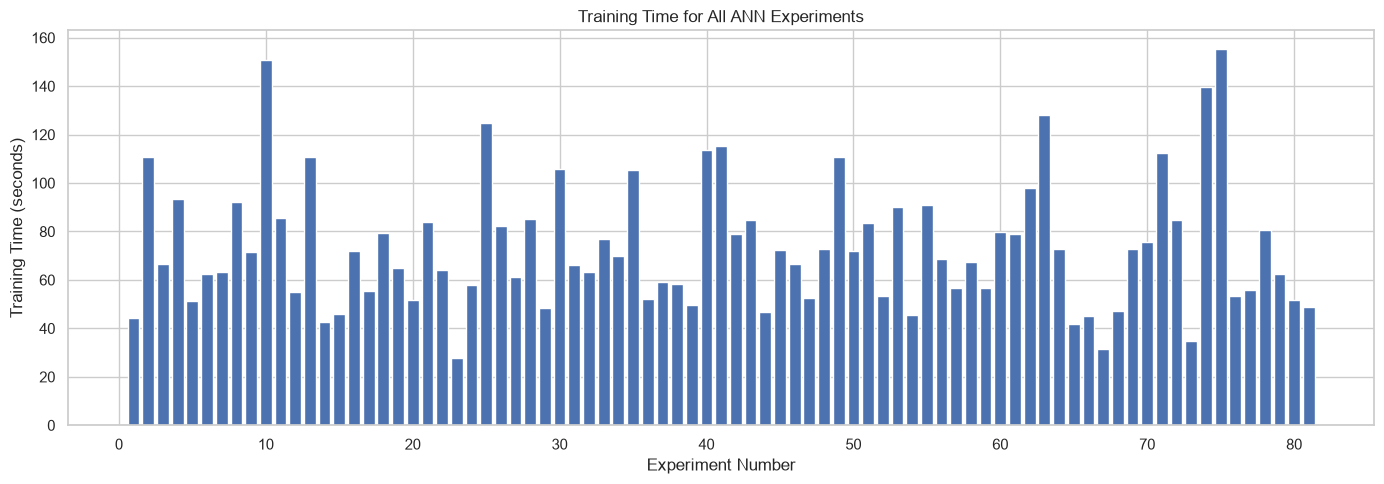

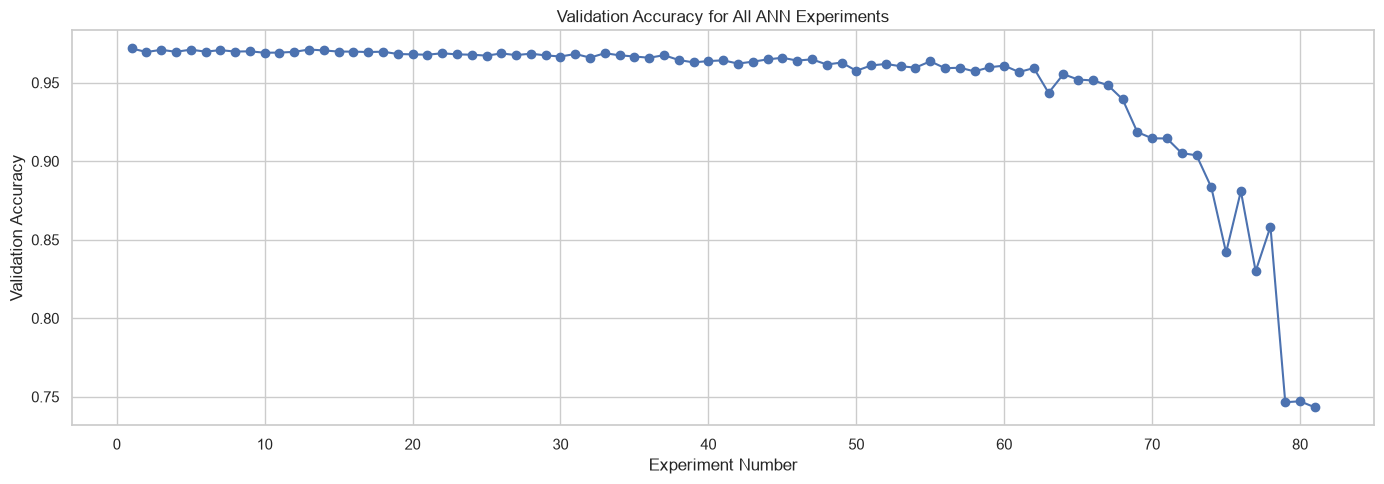

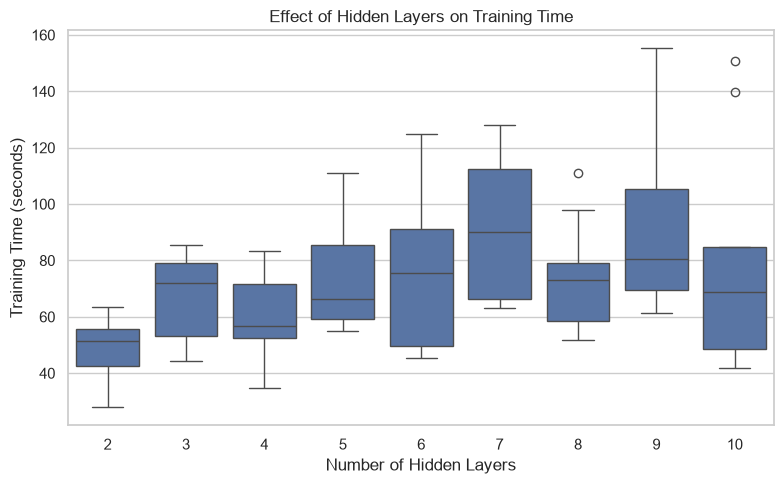

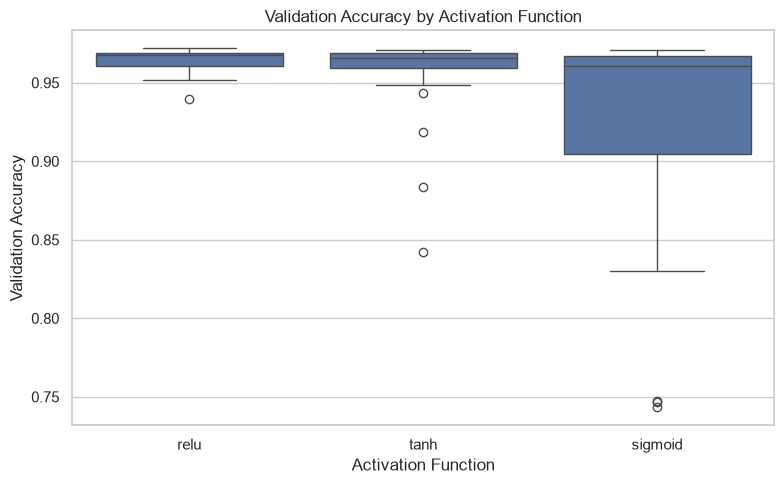

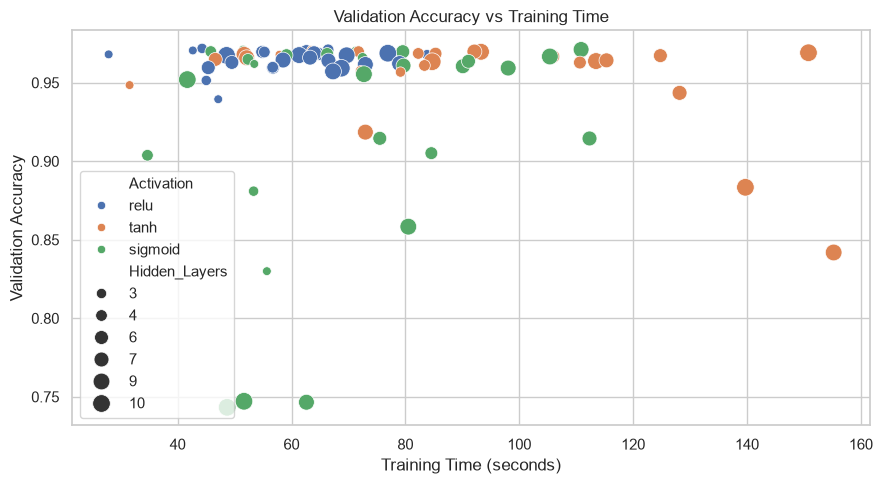

Successfully generated 5 plots!
Number of experiments: 81
All plots saved in the ANN_Plots folder.


In [31]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load results if not already available
if 'results_df' not in globals():
    results_df = pd.read_csv('ANN_computation_results.csv')

results_df.columns = results_df.columns.str.strip()

# Use your actual column names
time_col = 'Training_Time_Seconds'
accuracy_col = 'Validation_Accuracy'
layers_col = 'Hidden_Layers'
activation_col = 'Activation'
lr_col = 'Learning_Rate'

os.makedirs('ANN_Plots', exist_ok=True)
sns.set_theme(style='whitegrid')

# Plot 1: Training time for all experiments
plt.figure(figsize=(14, 5))
plt.bar(range(1, len(results_df) + 1), results_df[time_col])
plt.xlabel('Experiment Number')
plt.ylabel('Training Time (seconds)')
plt.title('Training Time for All ANN Experiments')
plt.tight_layout()
plt.savefig('ANN_Plots/1_Training_Time.png', dpi=300)
plt.show()

# Plot 2: Validation accuracy for all experiments
plt.figure(figsize=(14, 5))
plt.plot(range(1, len(results_df) + 1),
         results_df[accuracy_col], marker='o')
plt.xlabel('Experiment Number')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy for All ANN Experiments')
plt.tight_layout()
plt.savefig('ANN_Plots/2_Validation_Accuracy.png', dpi=300)
plt.show()

# Plot 3: Hidden layers vs training time
plt.figure(figsize=(8, 5))
sns.boxplot(data=results_df, x=layers_col, y=time_col)
plt.xlabel('Number of Hidden Layers')
plt.ylabel('Training Time (seconds)')
plt.title('Effect of Hidden Layers on Training Time')
plt.tight_layout()
plt.savefig('ANN_Plots/3_Hidden_Layers_Time.png', dpi=300)
plt.show()

# Plot 4: Activation function vs validation accuracy
plt.figure(figsize=(8, 5))
sns.boxplot(data=results_df, x=activation_col, y=accuracy_col)
plt.xlabel('Activation Function')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy by Activation Function')
plt.tight_layout()
plt.savefig('ANN_Plots/4_Activation_Accuracy.png', dpi=300)
plt.show()

# Plot 5: Validation accuracy vs training time
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=results_df,
    x=time_col,
    y=accuracy_col,
    hue=activation_col,
    size=layers_col,
    sizes=(40, 160)
)
plt.xlabel('Training Time (seconds)')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy vs Training Time')
plt.tight_layout()
plt.savefig('ANN_Plots/5_Accuracy_vs_Time.png', dpi=300)
plt.show()

print("Successfully generated 5 plots!")
print("Number of experiments:", len(results_df))
print("All plots saved in the ANN_Plots folder.")
